In [1]:
import polars as pl

## Data reading

In [2]:
DATA_DIR = "data"

In [3]:
df_taxi_zones = pl.scan_csv(f"{DATA_DIR}/taxi_zone_lookup.csv")

In [4]:
dfs = []
for month in range(12, 13):
    df = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet")
    df = df.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    dfs.append(df)
df = pl.concat(dfs)

Include rides only within specific date.

In [5]:
df = df.filter(
    pl.col("tpep_pickup_datetime").dt.year() == 2024,
    pl.col("tpep_dropoff_datetime") <= pl.datetime(2025, 1, 1),
)

In [6]:
df = df.with_columns(
    pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
    pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
)

Optimize data types (integers and one categorical string column).

In [7]:
df = df.with_columns(
    pl.col("passenger_count", "RatecodeID", "payment_type", "VendorID").cast(pl.UInt8),
    pl.col("PULocationID", "DOLocationID").cast(pl.UInt16),
    pl.col("store_and_fwd_flag").cast(pl.Enum(["N", "Y"])),
)

## Data cleaning and filtering

Fill `NULL` values.

In [8]:
df = df.with_columns(pl.col("passenger_count").fill_null(1))

Remove rides with zero passengers.

In [9]:
df = df.filter(pl.col("passenger_count") > 0)

Clip number of passengers.

In [10]:
df = df.with_columns(pl.col("passenger_count").clip(upper_bound=6))

Remove rides lasting over 2 hours.

In [11]:
trip_duration = pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")

df = df.filter(
    trip_duration > pl.duration(seconds=0),
    trip_duration.dt.total_hours() <= pl.duration(hours=2),
)

Replace money related columns with absolute value and remove rides with over 1000 dollars costs.

In [12]:
MONEY_COLS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

In [13]:
df = df.with_columns(pl.col(MONEY_COLS).abs())

In [14]:
df = df.filter(pl.max_horizontal(MONEY_COLS) <= 1000)

Remove rows with values of `RatecodeID` or `VendorID` missing or outside those defined in the data dictionary.

In [15]:
df = df.filter(
    pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99]),
    pl.col("VendorID").is_in([1, 2, 6, 7]),
)

## Data transformation

Combine payment type values.

In [16]:
df = df.with_columns(pl.col("payment_type").replace({4: 3, 5: 3, 6: 3}))

PAYMENT_TYPES = {
    "Flex Fare trip": 0,
    "Credit card": 1,
    "Cash": 2,
    "Other": 3,
}

Replace `PULocationID` and `DOLocationID` with borough names by joining taxi zone lookup and removing unnecessary columns.

In [17]:
zones = df_taxi_zones.select(
    pl.col("LocationID").cast(pl.UInt16),
    pl.col("Borough"),
)

df = (
    df.join(
        zones.rename(
            {
                "LocationID": "PULocationID",
                "Borough": "PU_Borough",
            }
        ),
        on="PULocationID",
        how="left",
    )
    .join(
        zones.rename(
            {
                "LocationID": "DOLocationID",
                "Borough": "DO_Borough",
            }
        ),
        on="DOLocationID",
        how="left",
    )
    .drop("PULocationID", "DOLocationID")
)

Add boolean variable `is_airport_ride`, true if there is non-zero airport fee.

In [18]:
is_airport_ride = pl.col("Airport_fee").fill_null(0.0) > 0.0

df = df.with_columns(is_airport_ride.alias("is_airport_ride"))

Add boolean variable `is_rush_hour`, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays.

In [19]:
is_weekday = pl.col("tpep_pickup_datetime").dt.weekday() <= 5

is_morning_rush = (
    pl.col("tpep_pickup_datetime")
    .dt.time()
    .is_between(pl.time(6, 30), pl.time(9, 30), closed="left")
)
is_evening_rush = (
    pl.col("tpep_pickup_datetime")
    .dt.time()
    .is_between(pl.time(15, 30), pl.time(20, 0), closed="left")
)

is_rush_hour = is_weekday & (is_morning_rush | is_evening_rush)

df = df.with_columns(is_rush_hour.alias("is_rush_hour"))

## Feature extraction

In [20]:
df = df.collect()

Apply dummy encoding to features: payment type, pickup borough, dropoff borough.

In [21]:
df = df.to_dummies(
    columns=["payment_type", "PU_Borough", "DO_Borough"],
    drop_first=True,
)

Add integer variables for counting daily events: total number of rides (target variable), number of airport rides, number of rush hour rides.

Add features aggregating daily rides information: average fare amount, median distance, sum of total amounts, total amount paid by card, cash, and other, total congestion surcharge, total number of passengers.

In [22]:
import polars.selectors as cs

PAYMENT_NAMES = {f"payment_type_{code}": name for name, code in PAYMENT_TYPES.items()}

df_daily = (
    df.group_by(pl.col("tpep_pickup_datetime").dt.date().alias("date"))
    .agg(
        pl.len().alias("total_rides"),
        pl.col("is_airport_ride").sum().alias("airport_rides"),
        pl.col("is_rush_hour").sum().alias("rush_hour_rides"),
        pl.col("fare_amount").mean().alias("fare_amount_mean"),
        pl.col("trip_distance").median().alias("trip_distance_median"),
        pl.col("total_amount").sum().alias("total_amount_sum"),
        pl.col("congestion_surcharge").sum().alias("congestion_surcharge_sum"),
        pl.col("passenger_count").sum().alias("passenger_count_sum"),
        # Total amount paid for given payment type
        (cs.starts_with("payment_type_") * pl.col("total_amount"))
        .sum()
        .name.map(
            lambda c: "total_amount_" + PAYMENT_NAMES[c].lower().replace(" ", "_")
        ),
    )
    .sort("date")
)

Add time features: `quarter`, `month`, `day_of_month`, `day_of_week`, `is_weekend` (boolean).

In [23]:
df_daily = df_daily.with_columns(
    pl.col("date").dt.quarter().alias("quarter"),
    pl.col("date").dt.month().alias("month"),
    pl.col("date").dt.day().alias("day_of_month"),
    pl.col("date").dt.weekday().alias("day_of_week"),
    (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
)

Exclude other columns, unnecessary for machine learning, e.g. IDs, timestamps, unused financial information.

In [24]:
# df_daily already contains required columns, without redundant, additional from raw df, so we skip this part.

# df = df.drop("VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "RatecodeID", "store_and_fwd_flag", "mta_tax", "tip_amount", "tolls_amount", "improvement_surcharge", "Airport_fee", "extra")

Save results as `dataset.parquet` file.

In [25]:
df_daily.write_parquet("./data/dataset.parquet")

## Data anylysis

In [26]:
dataset = pl.read_parquet("./data/dataset.parquet")

In [27]:
dataset.shape

(32, 16)

In [28]:
dataset.schema

Schema([('date', Date),
        ('total_rides', UInt32),
        ('airport_rides', UInt32),
        ('rush_hour_rides', UInt32),
        ('fare_amount_mean', Float64),
        ('trip_distance_median', Float64),
        ('total_amount_sum', Float64),
        ('congestion_surcharge_sum', Float64),
        ('passenger_count_sum', Int64),
        ('total_amount_cash', Float64),
        ('total_amount_other', Float64),
        ('quarter', Int8),
        ('month', Int8),
        ('day_of_month', Int8),
        ('day_of_week', Int8),
        ('is_weekend', Boolean)])

In [29]:
display(dataset.head())
display(dataset.describe())

date,total_rides,airport_rides,rush_hour_rides,fare_amount_mean,trip_distance_median,total_amount_sum,congestion_surcharge_sum,passenger_count_sum,total_amount_cash,total_amount_other,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,i64,f64,f64,i8,i8,i8,i8,bool
2024-11-30,26,2,0,18.338462,2.23,735.62,65.0,35,0.0,0.0,4,11,30,6,true
2024-12-01,88249,13975,0,22.486885,1.87,2.8235e6,196968.5,125742,332881.04,104328.42,4,12,1,7,true
2024-12-02,104804,14941,44891,22.109823,1.72,3.3768e6,235650.0,133720,397725.4,97575.31,4,12,2,1,false
2024-12-03,120531,12809,50171,20.949857,1.67,3.7032e6,276285.0,151621,409135.1,105591.13,4,12,3,2,false
2024-12-04,124098,11078,50886,20.892714,1.64,3.7986e6,286752.5,156739,400205.07,101026.03,4,12,4,3,false


statistic,date,total_rides,airport_rides,rush_hour_rides,fare_amount_mean,trip_distance_median,total_amount_sum,congestion_surcharge_sum,passenger_count_sum,total_amount_cash,total_amount_other,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""32""",32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-12-15 12:00:00""",103448.375,8235.40625,29835.53125,20.348727,1.670625,3.0632e6,238737.804688,142233.125,382983.034375,101200.064063,4.0,11.96875,16.4375,4.0,0.3125
"""std""",null,31363.425613,3336.471865,22553.38369,1.266752,0.146132,954740.797219,74621.546422,38816.74339,78409.500623,22439.279597,0.0,0.176777,9.280356,2.109885,null
"""min""","""2024-11-30""",26.0,2.0,0.0,17.608675,1.5,735.62,65.0,35.0,0.0,0.0,4.0,11.0,1.0,1.0,0.0
"""25%""","""2024-12-08""",82342.0,6338.0,0.0,19.479795,1.59,2.4582e6,187432.5,122722.0,380752.16,97575.31,4.0,12.0,9.0,2.0,null
"""50%""","""2024-12-16""",110277.0,7757.0,34554.0,20.42042,1.62,3.3768e6,254562.5,153367.0,399941.73,105591.13,4.0,12.0,17.0,4.0,null
"""75%""","""2024-12-23""",126635.0,11078.0,50886.0,21.326291,1.72,3.7032e6,296277.5,167322.0,418757.95,110927.29,4.0,12.0,24.0,6.0,null
"""max""","""2024-12-31""",142040.0,14941.0,56753.0,22.486885,2.23,4.4963e6,330652.5,199622.0,445234.58,123977.41,4.0,12.0,31.0,7.0,1.0


In [30]:
dataset_pd = dataset.sort("date").to_pandas()

<Axes: title={'center': 'Distribution of daily rides'}, xlabel='Daily number of rides', ylabel='Number of days'>

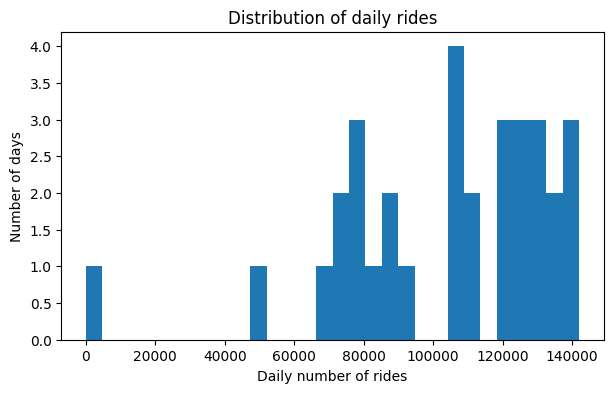

In [31]:
dataset_pd["total_rides"].plot(
    kind="hist",
    bins=30,
    figsize=(7, 4),
    xlabel="Daily number of rides",
    ylabel="Number of days",
    title="Distribution of daily rides",
)

<Axes: title={'center': 'Daily number of rides'}, xlabel='Date', ylabel='Number of rides'>

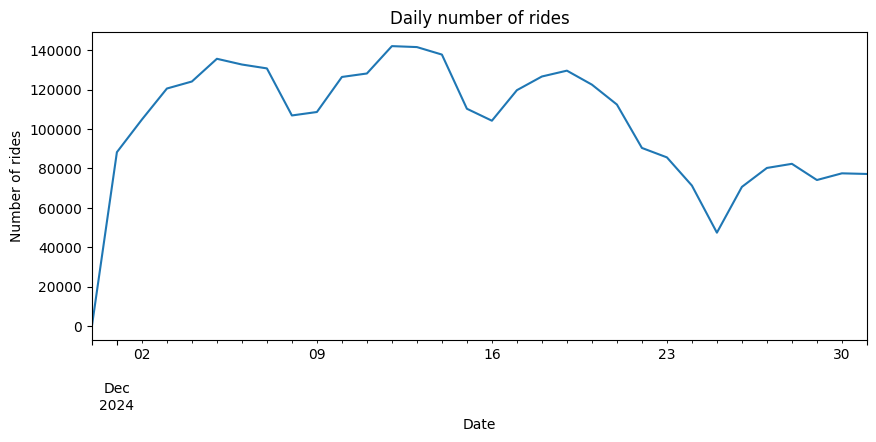

In [32]:
dataset_pd.plot(
    x="date",
    y="total_rides",
    kind="line",
    figsize=(10, 4),
    legend=False,
    xlabel="Date",
    ylabel="Number of rides",
    title="Daily number of rides",
)